In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Now we want to compare with the TENDL evaluated library of the same Lu-176 -> Lu-177 reaction

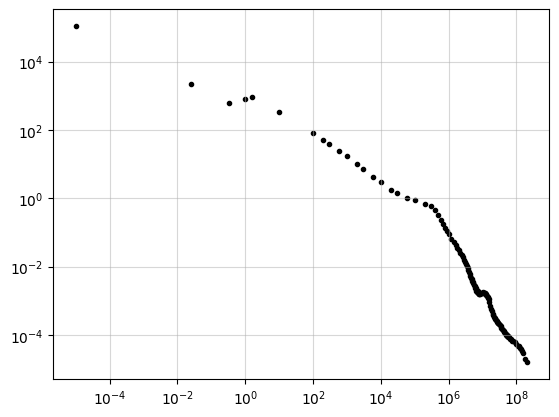

In [2]:
data = pd.read_csv(
        'TENDL-test-data.txt',
        comment='#',
        sep=r'\s+',
        header=None,
        names=['E', 'xs', 'gamma_xs', 'xs_res_prod']
                   
)

## Assign variables
energy=data['E'] * 1e6
cross_section = data['xs'] / 1000

plt.figure()
plt.scatter(energy, cross_section, marker='.', color='black')
plt.xscale('log')
plt.yscale('log')
plt.grid(which='both', alpha=0.5)
plt.show()

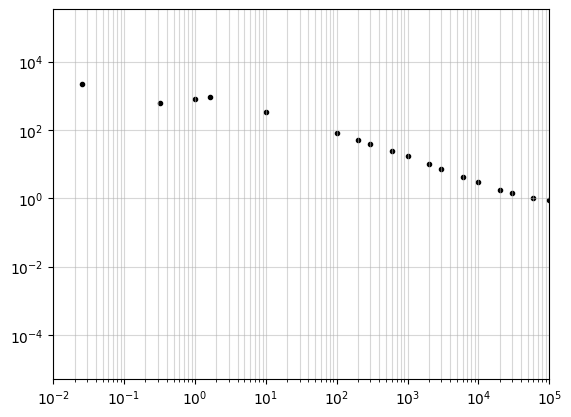

In [3]:
### Looks nothing like EXFOR data..
### Maybe want to look in the same energy region as EXFOR?

plt.figure()
plt.scatter(energy, cross_section, marker='.', color='black')
plt.xscale('log')
plt.yscale('log')
plt.grid(which='both', alpha=0.5, zorder=1)

plt.xlim(0.01, 1e5)
plt.show()

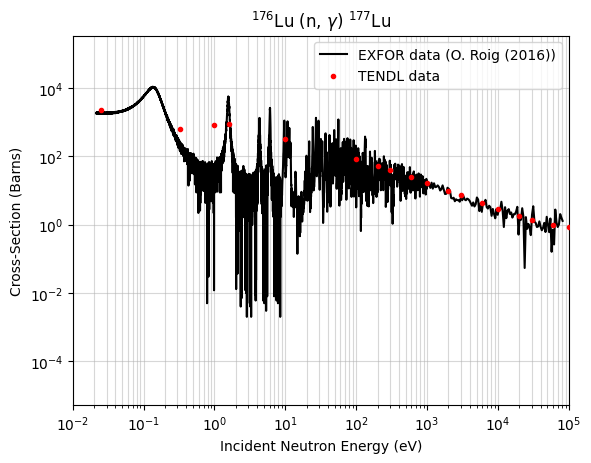

In [4]:
## What if we overlay the experimental measurement?

x4_data = pd.read_csv('exfordat2.csv')

## Extracting the columns
x4_cs = x4_data['DATA (B) 0.1']
x4_cs_sigma = x4_data['DATA-ERR (B) 0.911']
x4_energy = x4_data['EN (EV) 1.1']

plt.figure()
plt.plot(x4_energy, x4_cs, color='black', label='EXFOR data (O. Roig (2016))', zorder=2)

plt.scatter(energy, cross_section, color='red', label='TENDL data', zorder=3, marker='.')

plt.xscale('log')
plt.yscale('log')

plt.xlim(0.01, 1e5)
plt.grid(True, which='both', alpha=0.5, zorder=1)
plt.legend()

plt.xlabel('Incident Neutron Energy (eV)')
plt.ylabel('Cross-Section (Barns)')
plt.title(r'$^{176}$Lu (n, $\gamma$) $^{177}$Lu')
plt.show()

### JEFF Library

Now we want to investigate the JEFF library, this time the file type is .jeff which uses the ENDF format

In [27]:
from endf_parserpy import EndfParserFactory

parser = EndfParserFactory.create()
jeff_data = parser.parsefile('n_71-Lu-176g.jeff')

capture = jeff_data[3][102]


## xstable contains tabulated cross-section data

# xstable = capture['xstable']

# if isinstance(xstable, dict):
#     print(xstable.keys())

## Now we know where we can find the data

# jeff_energy = xstable['E']
# jeff_cross = xstable['xs']   

print(repr(capture['xstable'])[:2000])

{'E': [1e-05, 403.0, 403.0, 600.0, 1000.0, 2000.0, 3000.0, 6000.0, 10000.0, 20000.0, 30000.0, 60000.0, 100000.0, 200000.0, 300000.0, 400000.0, 500000.0, 600000.0, 700000.0, 800000.0, 900000.0, 1000000.0, 1200000.0, 1400000.0, 1600000.0, 1800000.0, 2000000.0, 2200000.0, 2400000.0, 2600000.0, 2800000.0, 3000000.0, 3200000.0, 3400000.0, 3600000.0, 3800000.0, 4000000.0, 4200000.0, 4400000.0, 4600000.0, 4800000.0, 5000000.0, 5200000.0, 5400000.0, 5600000.0, 5800000.0, 6000000.0, 6200000.0, 6400000.0, 6600000.0, 6800000.0, 7000000.0, 7200000.0, 7400000.0, 7600000.0, 7800000.0, 8000000.0, 8500000.0, 9000000.0, 9500000.0, 10000000.0, 10500000.0, 11000000.0, 11500000.0, 12000000.0, 12500000.0, 13000000.0, 13500000.0, 14000000.0, 14500000.0, 15000000.0, 16000000.0, 17000000.0, 18000000.0, 19000000.0, 20000000.0, 21000000.0, 22000000.0, 23000000.0, 24000000.0, 25000000.0, 26000000.0, 27000000.0, 28000000.0, 29000000.0, 30000000.0, 30000000.0, 200000000.0], 'xs': [0.0, 0.0, 34.36309, 24.33512, 16.

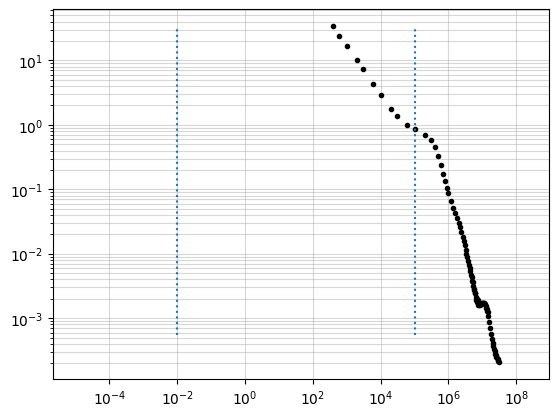

In [ ]:
plt.figure()

plt.scatter(jeff_energy, jeff_cross, marker='.', color='black', zorder=2)

plt.grid(True, which='both', alpha=0.5, zorder=1)
plt.xscale('log')
plt.yscale('log')

#plt.xlim(0.01, 1e5)
plt.vlines(0.01, ymin=np.min(jeff_cross)+0.00055, ymax= np.max(jeff_cross), linestyles=':')
plt.vlines(1e5, ymin= np.min(jeff_cross)+0.00055, ymax=np.max(jeff_cross), linestyles=':')
plt.show()

It seems that JEFF only contains a handful of data points in the region of interest, but we will plot them anyway

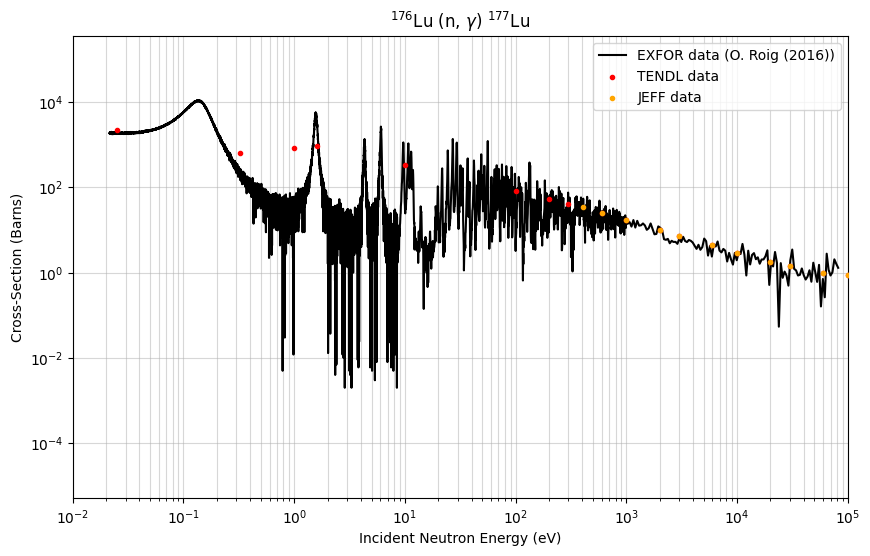

In [40]:
## What if we overlay the experimental measurement?

x4_data = pd.read_csv('exfordat2.csv')

## Extracting the columns
x4_cs = x4_data['DATA (B) 0.1']
x4_cs_sigma = x4_data['DATA-ERR (B) 0.911']
x4_energy = x4_data['EN (EV) 1.1']

plt.figure(figsize=(10,6))
plt.plot(x4_energy, x4_cs, color='black', label='EXFOR data (O. Roig (2016))', zorder=2)

plt.scatter(energy, cross_section, color='red', label='TENDL data', zorder=3, marker='.')

plt.scatter(jeff_energy, jeff_cross, color='orange', label='JEFF data', zorder=4, marker='.')

plt.xscale('log')
plt.yscale('log')

plt.xlim(0.01, 1e5)
plt.grid(True, which='both', alpha=0.5, zorder=1)
plt.legend()

plt.xlabel('Incident Neutron Energy (eV)')
plt.ylabel('Cross-Section (Barns)')
plt.title(r'$^{176}$Lu (n, $\gamma$) $^{177}$Lu')
plt.show()

Okay it looks like the JEFF data is the same as the TENDL data?

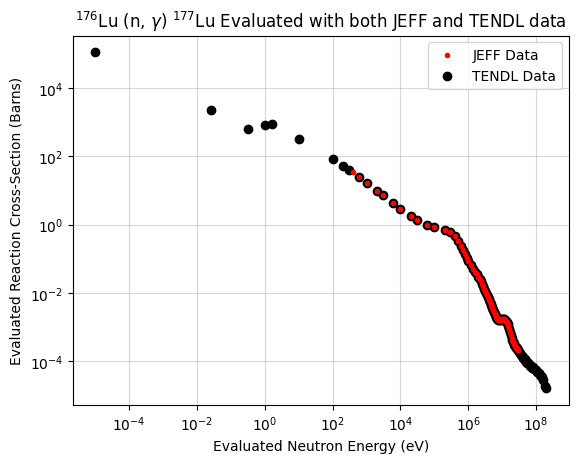

In [77]:
plt.figure()

plt.scatter(jeff_energy, jeff_cross, marker='.', color='red', zorder=3, label='JEFF Data')

plt.scatter(energy, cross_section, zorder=2, marker='o', color='black', label='TENDL Data')

plt.grid(True, which='both', alpha=0.5, zorder=1)
plt.xscale('log')
plt.yscale('log')

plt.legend()
plt.xlabel('Evaluated Neutron Energy (eV)')
plt.ylabel('Evaluated Reaction Cross-Section (Barns)')
plt.title(r'$^{176}$Lu (n, $\gamma$) $^{177}$Lu Evaluated with both JEFF and TENDL data')
#plt.xlim(0.01, 1e5)
# plt.vlines(0.01, ymin=np.min(jeff_cross)+0.00055, ymax= np.max(jeff_cross), linestyles=':')
# plt.vlines(1e5, ymin= np.min(jeff_cross)+0.00055, ymax=np.max(jeff_cross), linestyles=':')
plt.show()